In [6]:
# Импорт необходимых библиотек
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Простые графики мощности

In [4]:
# Проверка файлов с экспериментальными данными
folder_path=os.path.join("data", "Fire_calorimetry")
files = os.listdir(folder_path)
print(files)

['CLT_Room_Test_1.csv', 'CLT_Room_Test_2.csv']


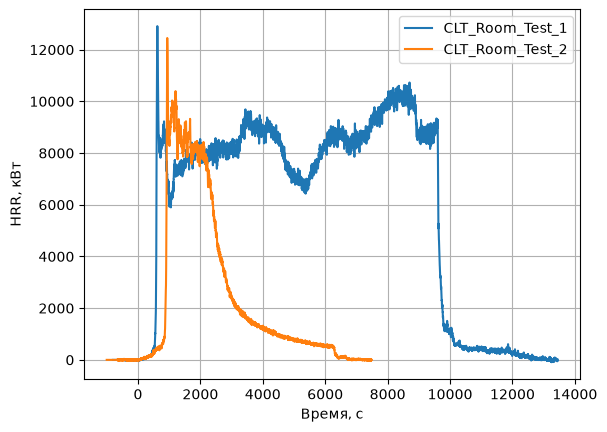

In [5]:
# Считывание экспериментальных данных
for file in files:
    # Считывание данных определенного формата
    if file.endswith('.csv'):
        file_path = os.path.join(folder_path, file)
        
        # Чтение данных
        calorimeter_df = pd.read_csv(file_path,header=0)
        
        # Построение графиков
        plt.plot(calorimeter_df['Time (s)'], 
                 calorimeter_df['Heat Release Rate (kW)'], 
                 label="_".join(file.split('.')[0:-1]))
        

# Метаданные графика
plt.xlabel("Время, с")
plt.ylabel("HRR, кВт")

plt.legend()
plt.grid()

# Показать график
plt.show() 

# Графики с аппроксимацией

In [7]:
# Функция развития пожара 
def alpha_t_squared(time, alpha):
    HRR = alpha * np.square(time)
    return HRR

In [8]:
# Расчетная мощность тепловыделения (HRR) при пожаре:
# Создание временного ряда
time_series = np.linspace(0,130)
# Ультра быстрое развитие
alpha=0.19 
HRR = alpha_t_squared(time_series, alpha)

In [9]:
# Проверка файлов с экспериментальными данными
folder_path=os.path.join("data", "Furniture_calorimetry")
files = os.listdir(folder_path)
print(files)

['LoveSeat.txt', 'SingleChair.txt', 'Sofa.txt']


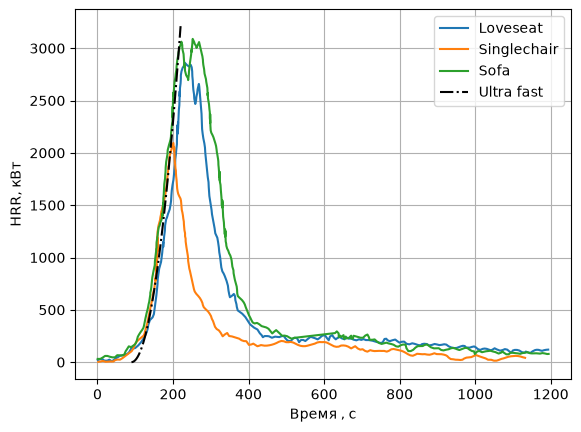

In [11]:
# Считывание экспериментальных данных
for file in files:
    # Считывание данных определенного формата.
    if file.endswith('.txt'):
        # Создание меток данных
        label = os.path.splitext(file )[0].split('_')[-1]  # Extract label from filename
        
        # Чтение данных.
        file_path = os.path.join(folder_path,file)
        furniture_df = pd.read_csv(file_path, header=0)
        
        if "Chair" in file:
            # Сдвиг ряды данных так, чтобы возрастающие участки совпали.
            time_shift = 60
        else:
            time_shift = 0
            
        # Построение графиков
        plt.plot(furniture_df['Time'] - time_shift, 
                 furniture_df['HRR'], 
                 label=label.capitalize())

# Постройте график результатов функции alpha_t_squared.
virtual_ignition_time = 90
plt.plot(time_series + virtual_ignition_time, 
         HRR, 
         color='k', linestyle='-.', 
         label="Ultra fast")


# Метаданные графика
plt.xlabel("Время , с")
plt.ylabel("HRR, кВт")
plt.legend()
plt.grid()

# Показать график
plt.show() 